# Détection de fraude dans les transactions bancaires avec le Machine Learning

Dans ce projet, je conçois un modèle de **classification binaire** pour détecter la fraude dans les transactions bancaires : chaque transaction est classée comme **légitime (0)** ou **frauduleuse (1)**.

Le dataset utilisé est le **Credit Card Fraud Detection dataset** du Machine Learning Group de l'**ULB** (Université Libre de Bruxelles), disponible [ici](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud?select=creditcard.csv). Il contient des transactions par carte bancaire réalisées par des porteurs européens en septembre 2013, soit **284 807 transactions**, dont seulement **492 fraudes (0,17 %)**. Les classes sont donc très déséquilibrées.

Pour des raisons de confidentialité, les variables `V1` à `V28` sont le résultat d'une **transformation PCA**. Seules `Time` et `Amount` sont restées inchangées. La variable cible `Class` vaut 1 pour une fraude et 0 pour une transaction légitime.

Je compare plusieurs algorithmes de classification, dont la **SVM**, la **régression logistique** et les **arbres de décision**, afin d'identifier le plus performant. Comme les fraudes sont rares, les modèles sont évalués avec des métriques adaptées au déséquilibre des classes : précision, rappel, F1-score et AUC.

# CHARGEMENT DES LIBS

In [ ]:
%pip install seaborn
%pip install imbalanced-learn

In [ ]:
# Necessary imports for this notebook
import os
import numpy as np
import pandas as pd
import datetime
import time
import random

# For plotting
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid', {'axes.facecolor': '0.9'})

from sklearn.svm import SVC, LinearSVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# metrics
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, average_precision_score)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, matthews_corrcoef, balanced_accuracy_score, fbeta_score

# CHARGEMENT DU DATASET

In [ ]:
url =  "../data/creditcard.csv"
df = pd.read_csv(url)

# INSPECTION DU DATASET

In [ ]:
df.shape

(7973, 31)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7973 entries, 0 to 7972
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    7973 non-null   int64  
 1   V1      7973 non-null   float64
 2   V2      7973 non-null   float64
 3   V3      7973 non-null   float64
 4   V4      7973 non-null   float64
 5   V5      7973 non-null   float64
 6   V6      7973 non-null   float64
 7   V7      7973 non-null   float64
 8   V8      7973 non-null   float64
 9   V9      7973 non-null   float64
 10  V10     7973 non-null   float64
 11  V11     7973 non-null   float64
 12  V12     7973 non-null   float64
 13  V13     7973 non-null   float64
 14  V14     7973 non-null   float64
 15  V15     7972 non-null   float64
 16  V16     7972 non-null   float64
 17  V17     7972 non-null   float64
 18  V18     7972 non-null   float64
 19  V19     7972 non-null   float64
 20  V20     7972 non-null   float64
 21  V21     7972 non-null   float64
 22  

In [ ]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,7973.000000,7973.000000,7973.000000,7973.000000,7973.000000,7973.000000,7973.000000,7973.000000,7973.000000,7973.000000,...,7972.000000,7972.000000,7972.000000,7972.000000,7972.000000,7972.000000,7972.000000,7972.000000,7972.000000,7972.000000
mean,4257.151261,-0.299740,0.295226,0.899355,0.215736,-0.025285,0.157286,-0.026445,-0.070525,0.655244,...,-0.053715,-0.165799,-0.035174,0.025977,0.088893,0.020256,0.016150,0.001161,65.413540,0.003136
std,3198.964299,1.498341,1.283914,1.090297,1.447057,1.167218,1.325015,1.063709,1.332568,1.156618,...,0.953498,0.654858,0.488322,0.601760,0.427505,0.517409,0.403570,0.275976,194.911169,0.055915
min,0.000000,-23.066842,-25.640527,-12.389545,-4.657545,-32.092129,-7.574798,-12.968670,-23.632502,-3.878658,...,-11.468435,-8.527145,-15.144340,-2.512377,-2.577363,-1.338556,-7.976100,-3.054085,0.000000,0.000000
25%,1531.000000,-1.046362,-0.237359,0.372435,-0.687521,-0.630525,-0.655399,-0.517733,-0.199794,-0.085635,...,-0.271837,-0.581473,-0.182989,-0.340419,-0.161009,-0.363180,-0.063198,-0.019081,4.617500,0.000000
50%,3635.000000,-0.416341,0.335446,0.948695,0.223379,-0.107337,-0.148669,0.004732,0.016128,0.613170,...,-0.130344,-0.167048,-0.046107,0.089606,0.115418,-0.015260,0.007101,0.018443,15.950000,0.000000
75%,6662.000000,1.122758,0.950582,1.597949,1.131542,0.405082,0.555200,0.527353,0.307111,1.294087,...,0.044823,0.250886,0.086806,0.421015,0.361249,0.329322,0.144700,0.080563,54.910000,0.000000
max,10981.000000,1.685314,8.261750,4.101716,7.380245,11.974269,21.393069,34.303177,3.877662,10.392889,...,22.588989,4.534454,13.876221,3.200201,5.525093,3.517346,4.173387,4.860769,7712.430000,1.000000


In [ ]:
df = df.dropna()

In [ ]:
df.dtypes

,0
Time,int64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


In [ ]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
total = df.isnull().sum().sort_values(ascending = False)
# total
percent = (df.isnull().sum()/df.isnull().count()*100).sort_values(ascending = False)
pd.concat([total, percent], axis=1, keys=['Total', 'Percent']).transpose()

,Amount,V28,V27,V26,V25,V24,V23,V22,V21,V20,...,V8,V11,V6,V5,V4,V3,V2,V1,Time,V7
Total,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Percent,0.012542,0.012542,0.012542,0.012542,0.012542,0.012542,0.012542,0.012542,0.012542,0.012542,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
class_group = df["Class"].value_counts()
total = len(df)

print(f"Fraud     : {class_group.get(1) * 100 / total:.2f} %")
print(f"Non Fraud : {class_group.get(0) * 100 / total:.2f} %")

Fraud     : 0.31 %
Non Fraud : 99.67 %


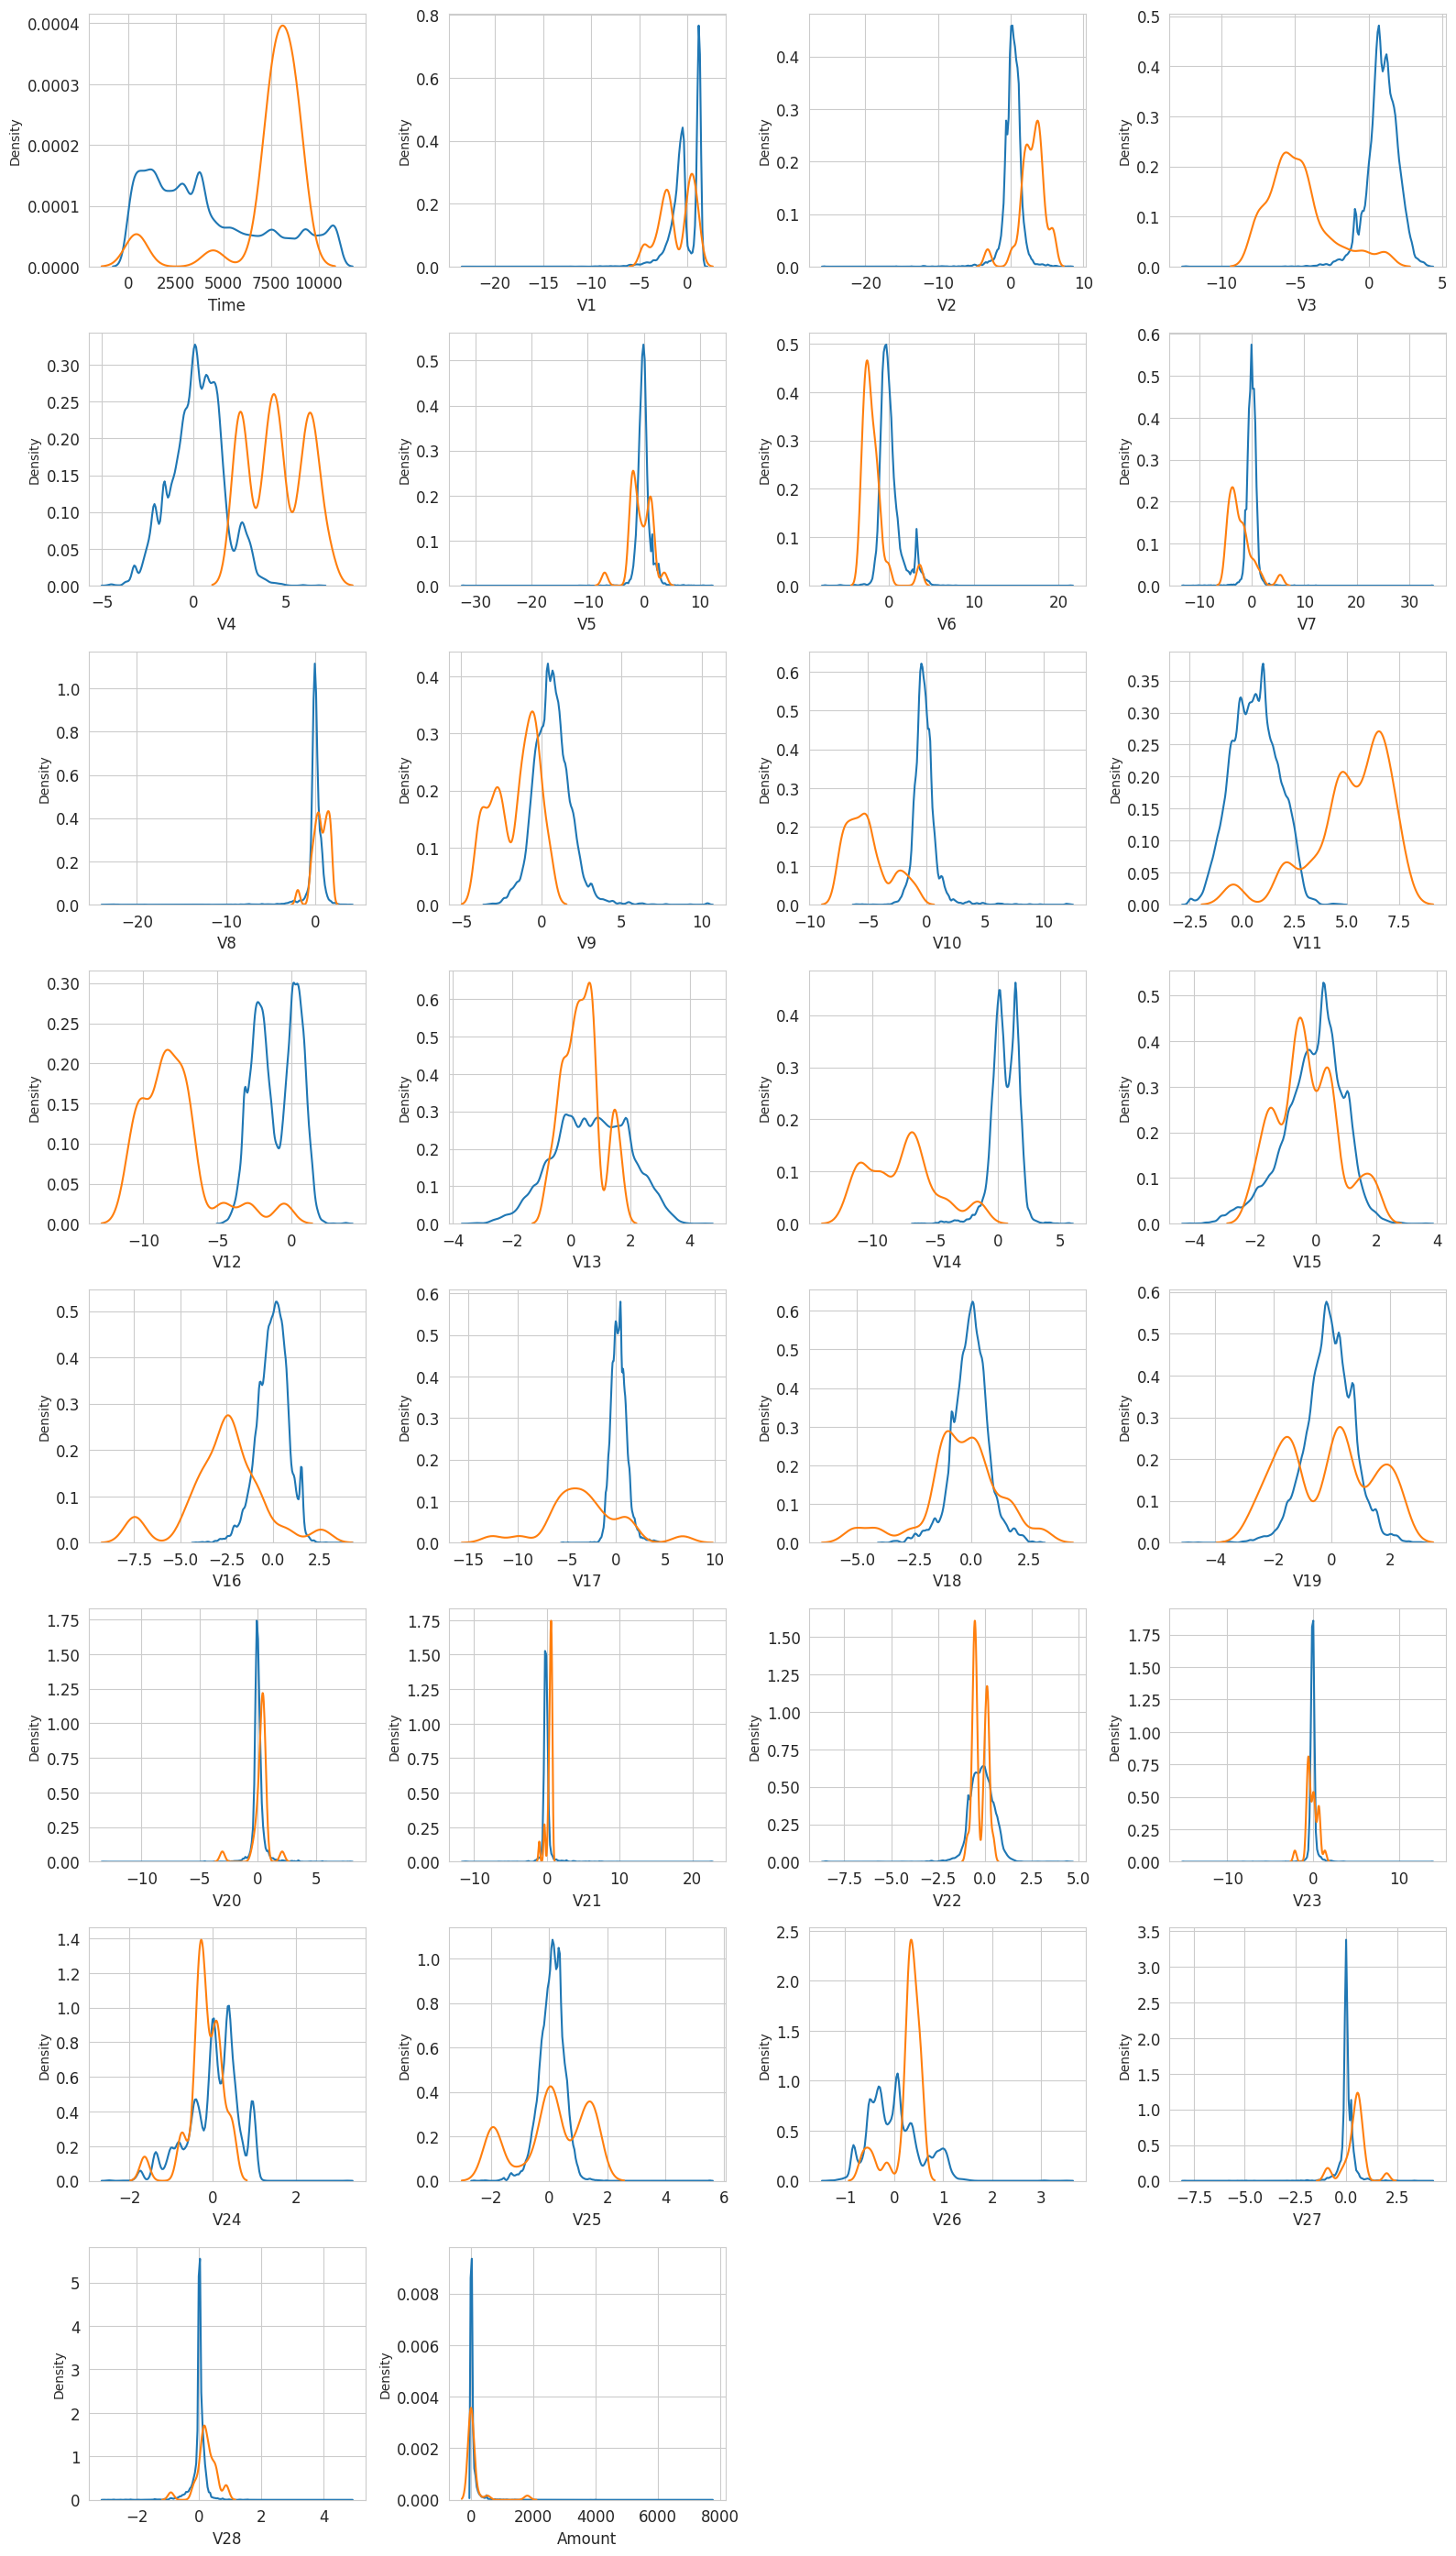

In [ ]:
var = [c for c in df.columns if c != 'Class']

t0 = df.loc[df['Class'] == 0]
t1 = df.loc[df['Class'] == 1]

sns.set_style('whitegrid')
fig, axes = plt.subplots(8, 4, figsize=(16, 28))

for ax, feature in zip(axes.flatten(), var):
    sns.kdeplot(t0[feature], bw_adjust=0.5, label="Class = 0", ax=ax)
    sns.kdeplot(t1[feature], bw_adjust=0.5, label="Class = 1", ax=ax)
    ax.set_xlabel(feature, fontsize=12)
    ax.tick_params(axis='both', which='major', labelsize=12)

# Masquer les axes inutilisés (la grille 8x4 a 32 cases)
for ax in axes.flatten()[len(var):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
# # Features correlation
# plt.figure(figsize = (14,14))
# plt.title('Credit Card Transactions features correlation plot (Pearson)')
# corr = df.corr()
# sns.heatmap(corr,xticklabels=corr.columns,yticklabels=corr.columns,linewidths=.1,cmap="Reds")
# plt.show()

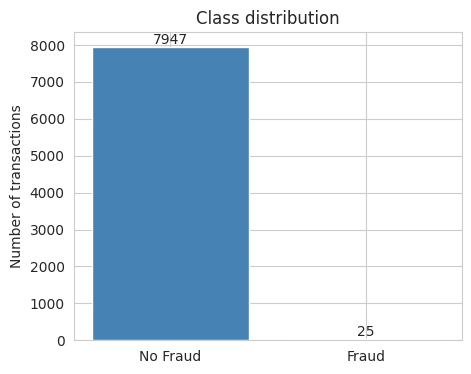

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))

counts = df["Class"].value_counts().sort_index()
# counts
bars = ax.bar(["No Fraud", "Fraud"], counts.values, color=["steelblue", "crimson"])
ax.bar_label(bars)
ax.set_title("Class distribution")
ax.set_ylabel("Number of transactions")

plt.show()

On peut constater que ce dataset est très déséquilibré. Pour pallier ce problème, nous utilisons plusieurs techniques de rééquilibrage et nous comparons leurs performances. Nous nous appuyons pour cela sur la bibliothèque [imbalanced-learn](https://imbalanced-learn.org/).

Les techniques testées sont regroupées en quatre familles.

**1. Sous-échantillonnage (*undersampling*)**

- **Random Undersampling** : on supprime aléatoirement des exemples de la classe majoritaire.
- **NearMiss** : on conserve les exemples majoritaires les plus proches des exemples minoritaires, selon un critère de distance.
- **Tomek Links** : on supprime les exemples majoritaires qui forment une paire de plus proches voisins avec un exemple minoritaire, ce qui nettoie la frontière entre les classes.
- **Edited Nearest Neighbours (ENN)** : on supprime les exemples majoritaires dont la classe diffère de celle de la majorité de leurs voisins.

**2. Sur-échantillonnage (*oversampling*)**

- **Random Oversampling** : on duplique aléatoirement des exemples de la classe minoritaire.
- **SMOTE** : on génère des exemples synthétiques par interpolation entre plus proches voisins de la classe minoritaire.
- **Borderline-SMOTE** : comme SMOTE, mais uniquement à partir des exemples minoritaires proches de la frontière de décision.
- **ADASYN** : on génère davantage d'exemples synthétiques dans les zones où les exemples minoritaires sont les plus difficiles à classer.

**3. Méthodes hybrides**

- **SMOTE + Tomek Links** : sur-échantillonnage par SMOTE, puis nettoyage de la frontière par suppression des Tomek Links.
- **SMOTE + ENN** : sur-échantillonnage par SMOTE, puis nettoyage plus agressif par ENN.

**4. Approches au niveau du modèle**

- **Pondération des classes** (`class_weight="balanced"`) : on pénalise davantage les erreurs commises sur la classe minoritaire, sans modifier les données.
- **Classifieurs d'ensemble adaptés** (*Balanced Random Forest*, *EasyEnsemble*) : chaque arbre ou chaque apprenant est entraîné sur un échantillon rééquilibré.

Ces approches sont comparées à l'aide de métriques adaptées aux données déséquilibrées (F1-score, rappel, précision, AUC-PR), car l'accuracy seule serait trompeuse. Le rééchantillonnage est appliqué uniquement sur l'ensemble d'entraînement, à l'intérieur de la validation croisée, afin d'éviter toute fuite de données vers l'ensemble de test.

# DECOUPAGE

In [ ]:
from collections import Counter

X = df_num = df.drop('Class', axis=1)
y = df['Class']
# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

print(f"Nombre de ligne dans le dataset original: {X.shape[0]}")
print(f"Nombre de ligne dans le dataset d'entrainement : {X_train.shape[0]}")
print(f"Nombre de ligne dans le dataset de test: {X_test.shape[0]}")
print(f"Repartition de classe dans le dataset original: {Counter(y)}")
print(f"Repartition de classe dans le dataset d'entrainement: {Counter(y_train)}")
print(f"Repartition de classe dans le dataset de test: {Counter(y_test)}")

Nombre de ligne dans le dataset original: 158601
Nombre de ligne dans le dataset d'entrainement : 106262
Nombre de ligne dans le dataset de test: 52339
Repartition de classe dans le dataset original: Counter({0.0: 158245, 1.0: 356})
Repartition de classe dans le dataset d'entrainement: Counter({0.0: 106025, 1.0: 237})
Repartition de classe dans le dataset de test: Counter({0.0: 52220, 1.0: 119})


#  SANS REECHANTILLONNAGE

In [ ]:
from sklearn.impute import SimpleImputer

algos = {
    'Logistic Regression': make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000),
    ),
    'XGBoost': XGBClassifier(random_state=42),
    'LightGBM': LGBMClassifier(random_state=42, class_weight="balanced", verbose=-1),
    'Random Forest': make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=100, random_state=0),
    ),
}

results = []

for algo_name, algo in algos.items():
    print(f"  Entraînement : {algo_name}...")
    model = clone(algo)  # modèle neuf pour chaque stratégie
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    # AUC-PR (si le modèle fournit des probabilités ou des scores)
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)

    results.append({
        'Algorithme': algo_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions),
        'F1-score': f1_score(y_test, predictions),
        'AUC-PR': average_precision_score(y_test, scores),
    })

df_results = pd.DataFrame(results)
df_results = df_results.sort_values('F1-score', ascending=False).reset_index(drop=True)
df_results.round(4)

  Entraînement : Logistic Regression...
  Entraînement : XGBoost...
  Entraînement : LightGBM...
  Entraînement : Random Forest...


,Algorithme,Accuracy,Precision,Recall,F1-score,AUC-PR
0,LightGBM,0.9995,0.9182,0.8487,0.8821,0.9042
1,Random Forest,0.9994,0.9394,0.7815,0.8532,0.8746
2,Logistic Regression,0.9988,0.8537,0.5882,0.6965,0.7926
3,XGBoost,0.9955,0.0000,0.0000,0.0000,0.0022


# AVEC REECHANTILLONNAGE

In [ ]:
from imblearn.under_sampling import RandomUnderSampler, NearMiss, TomekLinks, EditedNearestNeighbours
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN
from imblearn.combine import SMOTETomek, SMOTEENN


strategies = {
    'Random Undersampling': RandomUnderSampler(random_state=42),
    'Random Oversampling': RandomOverSampler(random_state=42),
    'SMOTE': SMOTE(random_state=42),
}

algos = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1),
}

In [ ]:
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, average_precision_score,
                             roc_auc_score, roc_curve)

results = []
roc_data = {}   # {(stratégie, algo): (fpr, tpr, auc)}

for strategy_name, strategy in strategies.items():
    print(f"Rééchantillonnage : {strategy_name}...")
    X_resampled, y_resampled = strategy.fit_resample(X_train, y_train)

    for algo_name, algo in algos.items():
        print(f"  Entraînement : {algo_name}...")
        model = clone(algo)
        model.fit(X_resampled, y_resampled)

        predictions = model.predict(X_test)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_test)[:, 1]
        else:
            scores = model.decision_function(X_test)

        # ROC
        fpr, tpr, _ = roc_curve(y_test, scores)
        auc_roc = roc_auc_score(y_test, scores)
        roc_data[(strategy_name, algo_name)] = (fpr, tpr, auc_roc)

        results.append({
            'Stratégie': strategy_name,
            'Algorithme': algo_name,
            'Accuracy': accuracy_score(y_test, predictions),
            'Precision': precision_score(y_test, predictions, zero_division=0),
            'Recall': recall_score(y_test, predictions),
            'F1-score': f1_score(y_test, predictions),
            'AUC-PR': average_precision_score(y_test, scores),
            'AUC-ROC': auc_roc,
        })

df_results = pd.DataFrame(results)
df_results = df_results.sort_values('F1-score', ascending=False).reset_index(drop=True)
df_results.round(4)

Rééchantillonnage : Random Undersampling...
  Entraînement : Logistic Regression...
  Entraînement : XGBoost...
  Entraînement : LightGBM...
  Entraînement : Random Forest...
Rééchantillonnage : Random Oversampling...
  Entraînement : Logistic Regression...
  Entraînement : XGBoost...
  Entraînement : LightGBM...
  Entraînement : Random Forest...
Rééchantillonnage : SMOTE...
  Entraînement : Logistic Regression...
  Entraînement : XGBoost...
  Entraînement : LightGBM...
  Entraînement : Random Forest...


,Stratégie,Algorithme,Accuracy,Precision,Recall,F1-score,AUC-PR,AUC-ROC
0,Random Oversampling,XGBoost,0.9995,0.9524,0.8403,0.8929,0.9070,0.9836
1,Random Oversampling,LightGBM,0.9995,0.9340,0.8319,0.8800,0.8703,0.9620
2,SMOTE,XGBoost,0.9994,0.8814,0.8739,0.8776,0.9075,0.9837
3,Random Oversampling,Random Forest,0.9995,0.9789,0.7815,0.8692,0.8937,0.9691
4,SMOTE,LightGBM,0.9994,0.8413,0.8908,0.8653,0.9006,0.9835
5,SMOTE,Random Forest,0.9994,0.8850,0.8403,0.8621,0.8854,0.9794
6,SMOTE,Logistic Regression,0.9910,0.1927,0.9328,0.3194,0.7544,0.9886
7,Random Oversampling,Logistic Regression,0.9768,0.0842,0.9328,0.1544,0.7481,0.9856
8,Random Undersampling,Random Forest,0.9758,0.0811,0.9328,0.1492,0.7595,0.9824
9,Random Undersampling,Logistic Regression,0.9702,0.0668,0.9328,0.1247,0.5628,0.9832


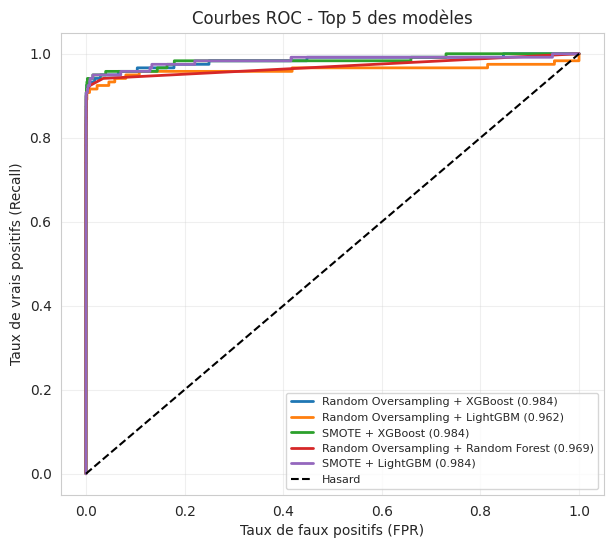

In [ ]:
plt.figure(figsize=(7, 6))
for _, row in df_results.head(5).iterrows():
    key = (row['Stratégie'], row['Algorithme'])
    fpr, tpr, auc_roc = roc_data[key]
    plt.plot(fpr, tpr, lw=2, label=f"{key[0]} + {key[1]} ({auc_roc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label="Hasard")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (Recall)")
plt.title("Courbes ROC - Top 5 des modèles")
plt.legend(fontsize=8, loc="lower right")
plt.grid(alpha=0.3)
plt.show()

On observe que le sous-échantillonnage (undersampling) produit globalement les résultats les plus faibles, quel que soit l'algorithme utilisé. Par ailleurs, le rééchantillonnage améliore la précision ainsi que le F-score.

# ENTRAINEMENT DU MODEL FINAL

In [ ]:
import joblib
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, confusion_matrix

# 1. Rééchantillonnage sur le TRAIN uniquement
ros = RandomOverSampler(random_state=42)
X_res, y_res = ros.fit_resample(X_train, y_train)

# 2. Modèle final (mêmes hyperparamètres que ceux testés)
final_model = XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)
final_model.fit(X_res, y_res)

# 3. Évaluation sur le test (une seule fois)
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

print("AUC-PR :", average_precision_score(y_test, y_proba))
print(confusion_matrix(y_test, y_pred))

# 4. Sauvegarde
joblib.dump(final_model, "../models/final_model_xgb_ros.pkl")

AUC-PR : 0.9069842016837818
[[52215     5]
 [   19   100]]


['final_model_xgb_ros.pkl']

# SOURECS

*   https://fraud-detection-handbook.github.io/fraud-detection-handbook/Chapter_5_ModelValidationAndSelection/ValidationStrategies.html
*   https://cs229.stanford.edu/proj2018/report/261.pdf
* https://arxiv.org/pdf/2108.00071
* https://www.denog.de/media/DENOG12/Day0_workshop_Monitoring%20with%20Grafana.pdf
